# DSF4E Challenge: Explorative Data Analysis
## Getting Started

Welcome to the DSF4E Challenge on Explorative Data Analysis! This notebook will guide you through the initial steps to get started with your data analysis journey.

For general information about the challenge, please refer to the introduction presentation provided alongside the challenge materials.

In case of any questions or clarifications needed during the challenge, feel free to reach out via the ILIAS forum.

In the files provided for this challenge, you will find:

* A dataset in CSV format containing customer, order and product information.
* A directory containing the dxf-files of all relevant products.
* A Python file with helper functions to load, process, and visualize the dxf-files.
* A requirements.txt file to help you set up your Python environment.

In [19]:
%cd "C:\Users\trish\Desktop\laser cut\Challange_1_LaserCut-GmbH\DSF4E_Challenge1-2"

C:\Users\trish\Desktop\laser cut\Challange_1_LaserCut-GmbH\DSF4E_Challenge1-2


## Setting up your environment

Please make sure all required packages are installed in your Python environment. You can do this by running the following command:

In [6]:
%pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


## Using the provided implementations

Alongside the challenge materials, the python source code file `helpers.py` is provided. This file contains several helper functions to facilitate your work with the dxf-files. 

If working in a Jupyter Notebook located in the same directory as `helpers.py`, you can import the helper functions as follows:

In [7]:
from helpers import *

The above command should load all functions defined in `helpers.py` into your notebook's namespace, allowing you to use them directly.

If your notebook is located in a different directory, you may need to adjust the import statement accordingly.

You will find the functions useful in loading and visualizing the dxf files. Additionally, functions for the computation of some complexity-related features are also provided.

## About the dxf files

The dxf files provided in the dataset represent 2D technical drawings of various products. These files can be visualized and analyzed using the helper functions provided in `helpers.py`.

Each dxf file contains geometric information about the product, which can be used to derive various features relevant to the challenge. The helper functions will assist you in loading these files and extracting necessary information for your analysis.

Here is an example of how to use one of the helper functions to plot a dxf file:

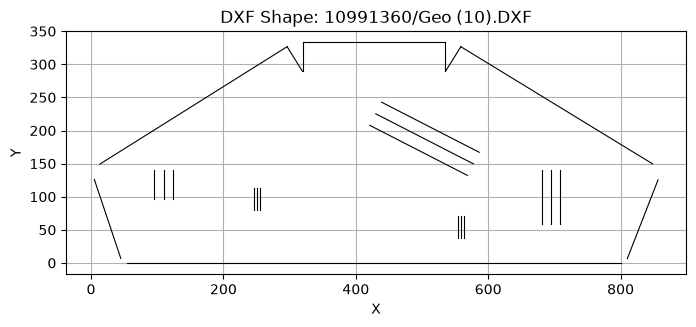

In [8]:
plot_dxf("10991360/Geo (10).DXF")

## Data Linking and Cleanup

You can use the provided functions, to extract the required information from the dxf files and link them to the tabular data.

The pandas DataFrame-method `join` might be useful to link different DataFrames based on a common index. Below, you can find a simple example of how to use this method.

For details, please refer to the [pandas documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.join.html#pandas.DataFrame.join).

In [9]:
import pandas as pd

# Create two sample DataFrames
df1 = pd.DataFrame({
    'product_id': [1, 2, 3],
    'product_name': ['A', 'B', 'C']
})
df2 = pd.DataFrame({
    'product_id': [1, 2, 3],
    'price': [10.0, 20.0, 30.0]
}).set_index('product_id')

# Join the DataFrames on the index
df_joined = df1.join(df2, on='product_id')
df_joined

,product_id,product_name,price
0,1,A,10.0
1,2,B,20.0
2,3,C,30.0


Alternatively, the function `pd.merge` links DataFrames on one or more common columns (no index needed). With the
parameter `validate` you can let pandas check your assumptions about the keys: `validate="one_to_one"` raises an
error if a key appears more than once in one of the DataFrames, instead of silently duplicating rows. The parameter
`indicator=True` adds a column `_merge` that shows whether a row was found in both DataFrames or only in one of them.

For details, please refer to the [pandas documentation](https://pandas.pydata.org/docs/reference/api/pandas.merge.html).

In [10]:
# Merge on a common column and check that each key occurs only once on both sides
df_merged = pd.merge(df1, df2.reset_index(), on='product_id', how='outer',
                     validate='one_to_one', indicator=True)
df_merged

,product_id,product_name,price,_merge
0,1,A,10.0,both
1,2,B,20.0,both
2,3,C,30.0,both
